### Build a Basic ChatBot using Langgraph

- Langchain is used for straight forward pipline each task follows fixed sequence from input to output .It cannot take the complex decesions and also parallel processing.
- where as Langrpah is used for complex pipeline and take the decisions parallely and taking complex decisions 
- The Langraph uses two APIs to implement this complex workflows
  - 1.GraphAPI
      - main important thing in Graph API
          - 1.Node:Perform the actual work or computation
          - 2.Edge:Decide where execution should go next
          - 3.State:Stores the information that shared across the workflow that is called as stateGraph
  - 2.Functional API
- Reducer in langgrpah means it's a function that determines how new data should be updated or added to the existing state


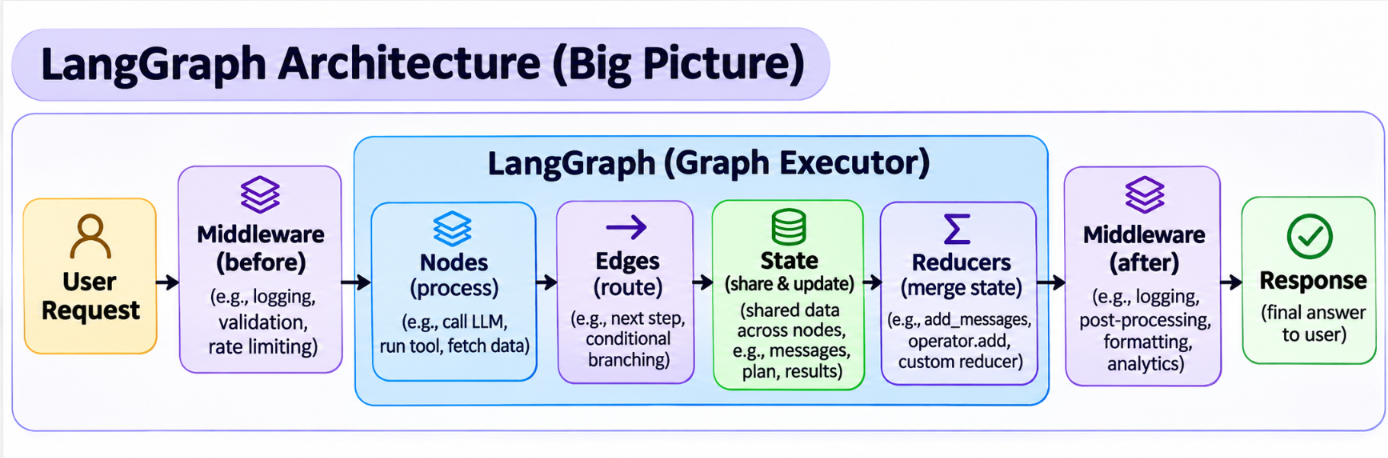


In [198]:
## import the required modules and functions

from typing_extensions import TypedDict,Annotated
from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages #it's one of the reducer


In [199]:
## Lets create the state
class State(TypedDict):
  messages:Annotated[list,add_messages]

In [200]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [201]:
# ## create the chat bot 
# ## first intialize the model
from langchain.agents import create_agent
from langchain.chat_models import init_chat_model
# llm=create_agent(
#   model='gpt-6-luna'
# ) ## it creates agent ,note: dont use this 
# llm=init_chat_model('gpt-6-luna') ## it creates a llm 
llm=init_chat_model('google_genai:gemini-3.5-flash-lite')
llm

ChatGoogleGenerativeAI(metadata={'lc_versions': {'langchain-core': '1.7.3', 'langchain': '1.4.7', 'langchain-google-genai': '4.4.2'}}, profile={'name': 'Gemini 3.5 Flash Lite', 'release_date': '2026-07-21', 'last_updated': '2026-07-21', 'open_weights': False, 'max_input_tokens': 1048576, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': True, 'audio_inputs': True, 'pdf_inputs': True, 'video_inputs': True, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': True, 'temperature': True, 'image_url_inputs': True, 'image_tool_message': True, 'tool_choice': True, 'reasoning_effort_levels': ['minimal', 'low', 'medium', 'high'], 'reasoning_effort_default': 'minimal'}, google_api_key=SecretStr('**********'), model='gemini-3.5-flash-lite', temperature=None, client=<google.genai.client.Client object at 0x000001CBD2D67690>, default_metadata=(), model_kwar

In [202]:
## node implementation
def chatbot(state:State):
    print("Received state:", state)
    print("Received messages:", state["messages"])
    # Step 1: Receive the current graph state.
    # The state contains the conversation history under the "messages" key.

    # Step 2: Extract all existing messages from the state.
    # Example: [HumanMessage(content="Hi")]

    # Step 3: Pass the conversation history to the LLM.
    # llm.invoke() sends these messages to the language model.
    # The LLM processes the conversation and generates an AI response.
    # Example: AIMessage(content="Hello! How can I help you?")

    # Step 4: Return the AI response as a dictionary.
    # "messages" is the state key that needs to be updated.
    # We wrap the AI response in a list because messages is a list.

    # Step 5: LangGraph uses the add_messages reducer to append
    # the new AI response to the existing conversation history.

    return {
        'messages':[llm.invoke(state['messages'])]
    }

In [203]:
## build the graph
graph_builder=StateGraph(State)

## create the node
graph_builder.add_node('llmchatbot',chatbot)

## create the edges
graph_builder.add_edge(START,'llmchatbot')
graph_builder.add_edge('llmchatbot',END)

## compile the graph
graph=graph_builder.compile()

# graph_builder.compile()
##Langraph prepares your execution workflow
#1.It checks whether the graph strcture is valid or not 
#2.Prepares the graph exeution structure

In [204]:
## invoke
from langchain.messages import HumanMessage
# response=graph.invoke({'messages':[HumanMessage(content='Hi')]})
response=graph.invoke({'messages':'Hi'})
response

Received state: {'messages': [HumanMessage(content='Hi', additional_kwargs={}, response_metadata={}, id='28a2b3c2-cade-410a-9e3b-f14df91325bf')]}
Received messages: [HumanMessage(content='Hi', additional_kwargs={}, response_metadata={}, id='28a2b3c2-cade-410a-9e3b-f14df91325bf')]


{'messages': [HumanMessage(content='Hi', additional_kwargs={}, response_metadata={}, id='28a2b3c2-cade-410a-9e3b-f14df91325bf'),
  AIMessage(content=[{'type': 'text', 'text': 'Hello! How can I help you today?', 'extras': {'signature': 'EmAKXgFpFH0T0V4OlXyTvA0CBbQqKZnoZjvoDiT3U2W1/AhGMsSkXtHiJBdmhGC9bcOWcZkWbd2mNCKsPYW6Ud5JIuhhRfXjkUBWGEqIfJdrBgmd9RhpVXeLz99tvECXpiA='}}], additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.5-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1a789-86e8-756e-b8c7-46ed5a08965e-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 2, 'output_tokens': 9, 'total_tokens': 11, 'input_token_details': {'cache_read': 0}})]}

In [205]:
## beautify the output
response['messages'][-1].content

[{'type': 'text',
  'text': 'Hello! How can I help you today?',
  'extras': {'signature': 'EmAKXgFpFH0T0V4OlXyTvA0CBbQqKZnoZjvoDiT3U2W1/AhGMsSkXtHiJBdmhGC9bcOWcZkWbd2mNCKsPYW6Ud5JIuhhRfXjkUBWGEqIfJdrBgmd9RhpVXeLz99tvECXpiA='}}]

### Chat Bot With Tool

#### This is the Flow
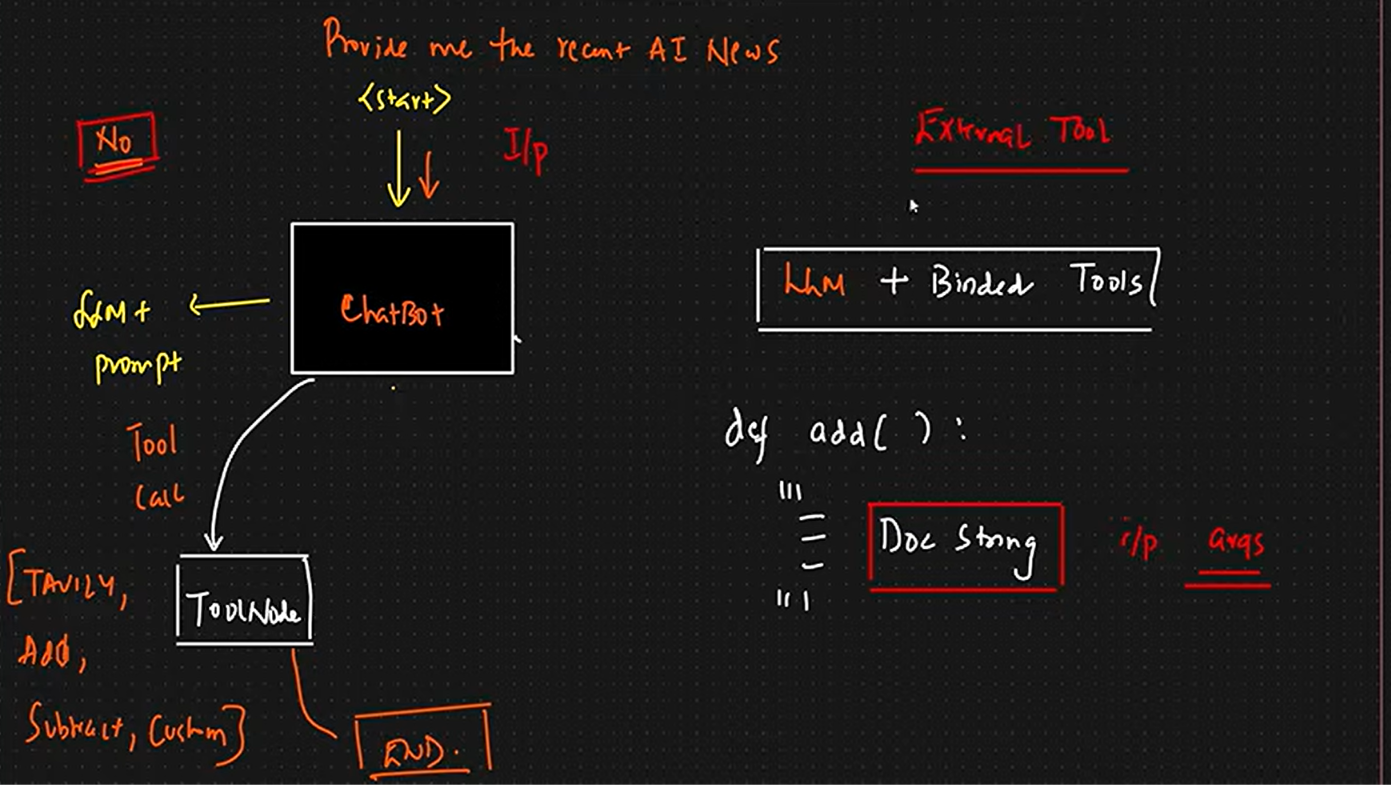

In [206]:
## builtin tool 
from langchain_tavily import TavilySearch # Its a websearch API
tool=TavilySearch(max_results=2)
tool.invoke('what is langgraph')

{'query': 'what is langgraph',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.geeksforgeeks.org/machine-learning/what-is-langgraph',
   'title': 'What is LangGraph - GeeksforGeeks',
   'content': 'LangGraph is an open-source framework from LangChain designed to build and manage AI agent workflows using graph-based structures. It allows developers to define workflows as nodes and edges, making complex agent interactions more structured, scalable and easier to control. [...] langgraph: Framework for building graph-based AI workflows.\n langchain: Popular toolkit for LLM-powered AI applications.\n google-generativeai: Google’s API for Generative AI (Gemini models).\n\n Python  ````\n! pip install langgraph langchain google - generativeai\n```` \n\n### Step 2: Setup Gemini API [...] ## Building a Simple Chatbot with LangGraph\n\nLangGraph makes it easy to build structured, stateful applications like chatbots. In this example we’ll learn how 

In [207]:
## custom tool
def multiply(a:int,b:int)->int:
   
   """Multiply a and b"""
   return a*b

In [208]:
## bind the tools with model
tools=[tool,multiply]
llm_with_tool=llm.bind_tools(tools)

In [209]:
## stateGraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## tools condition -->It checks whether latest llm response contains a tool call or not
## ToolNode-->It is used for executes tools request by llm

## Graph
graph_builder=StateGraph(State)

## node defination
def tool_calling_llm(state:State):
  return {
    'messages':[llm_with_tool.invoke(state['messages'])]
  }

## Create Nodes
graph_builder.add_node('tool_calling_llm',tool_calling_llm);
graph_builder.add_node('tools',ToolNode(tools))

## Create Edges
graph_builder.add_edge(START,'tool_calling_llm')
graph_builder.add_conditional_edges(
  'tool_calling_llm',
   tools_condition
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
)
graph_builder.add_edge('tools',END)

## compile the graph
graph=graph_builder.compile()




In [210]:
## invoke the graph
from langchain.messages import HumanMessage
response=graph.invoke({'messages':HumanMessage(
  content='what is the recent ai news'
)})

In [211]:
response


{'messages': [HumanMessage(content='what is the recent ai news', additional_kwargs={}, response_metadata={}, id='f8a67d08-297a-4475-b1b2-86592d089eb1'),
  AIMessage(content=[], additional_kwargs={'function_call': {'name': 'tavily_search', 'arguments': '{"query": "recent AI news major breakthroughs developments 2026", "search_depth": "advanced"}'}, '__gemini_function_call_thought_signatures__': {'call_401365': 'EmAKXgFpFH0TZqaBBCRT9vQikR5xPB+DUhK6TN9rAOFQfpgkFqVMySoWe7a/E+CLJs9Gf2CQZgQiZvV8pbLY8o76/SAaGP0LMbb4Pp5IVLtH0Rp2wzcYaGiz3S3lk+LuBps='}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.5-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1a789-b988-77da-9e4e-c03a28834d31-0', tool_calls=[{'name': 'tavily_search', 'args': {'query': 'recent AI news major breakthroughs developments 2026', 'search_depth': 'advanced'}, 'id': 'call_401365', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 1548, 'output_to

In [212]:
response['messages'][-1].content

'{"query": "recent AI news major breakthroughs developments 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.crescendo.ai/news/latest-ai-news-and-updates", "title": "The Latest AI News and Breakthroughs That Matter Most | News", "content": "Date: May 8, 2026\\n\\nSummary: Structural biology is experiencing transformative advances beyond AlphaFold 2, with two major breakthroughs reshaping the field. Microsoft\'s BioEmu employs generative diffusion frameworks to predict full protein conformational landscapes from sequences, generating thousands of models that represent Boltzmann-weighted ensembles. Simultaneously, AI-guided design platforms like BindCraft are democratizing protein binder development, achieving high experimental success rates with nanomolar affinity binders. These advances are being democratized through accessible platforms like Tamarind Bio and powered by AI agents, marking two new \\"AlphaFold moments\\" transforming bio

In [213]:
## want to show the pretty output
for m in response['messages']:
  m.pretty_print()

================================ Human Message =================================

what is the recent ai news
================================== Ai Message ==================================

[]
Tool Calls:
  tavily_search (call_401365)
 Call ID: call_401365
  Args:
    query: recent AI news major breakthroughs developments 2026
    search_depth: advanced
================================= Tool Message =================================
Name: tavily_search

{"query": "recent AI news major breakthroughs developments 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.crescendo.ai/news/latest-ai-news-and-updates", "title": "The Latest AI News and Breakthroughs That Matter Most | News", "content": "Date: May 8, 2026\n\nSummary: Structural biology is experiencing transformative advances beyond AlphaFold 2, with two major breakthroughs reshaping the field. Microsoft's BioEmu employs generative diffusion frameworks to predict full protein conformat

In [214]:
## Now call the another tool as well as 
response=graph.invoke({'messages':"what is the result 10 multiply by 20"})
response

{'messages': [HumanMessage(content='what is the result 10 multiply by 20', additional_kwargs={}, response_metadata={}, id='7c2c15f8-1b4e-458a-b340-682b573c398a'),
  AIMessage(content=[], additional_kwargs={'function_call': {'name': 'multiply', 'arguments': '{"b": 20, "a": 10}'}, '__gemini_function_call_thought_signatures__': {'call_267393': 'EmAKXgFpFH0T87zSYfZDV/rGpFiYsvJgAD2z+zSza04zSNRCLDFgmyjqiq593qH43qnoqr/tX7yWXftBgMRKlz47r7jjeV34yUzE3hetKBLYMLyjbw3V73OjCnbSg9FOKR4='}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.5-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1a78a-0c19-77ae-bb88-58027bb88ce0-0', tool_calls=[{'name': 'multiply', 'args': {'b': 20, 'a': 10}, 'id': 'call_267393', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 1554, 'output_tokens': 18, 'total_tokens': 1572, 'input_token_details': {'cache_read': 0}}),
  ToolMessage(content='200', name='multiply', id='a54737c2-8201-483b-b8ff

In [215]:
## want to show the pretty output
for m in response['messages']:
  m.pretty_print()

================================ Human Message =================================

what is the result 10 multiply by 20
================================== Ai Message ==================================

[]
Tool Calls:
  multiply (call_267393)
 Call ID: call_267393
  Args:
    b: 20
    a: 10
================================= Tool Message =================================
Name: multiply

200


In [216]:
## suppose if you call two two calls at a time 
response=graph.invoke({"messages":"Give me the recent ai news and then multiply 5 by 10"})
for m in response['messages']:
    m.pretty_print()

# but here it gives only one tool output only why??
# In order solve this problem ReAct Agent Architecture comes into the picture

================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
================================== Ai Message ==================================

[]
Tool Calls:
  tavily_search (call_313547)
 Call ID: call_313547
  Args:
    topic: news
    query: latest artificial intelligence news 2026
  multiply (call_313548)
 Call ID: call_313548
  Args:
    b: 10
    a: 5
================================= Tool Message =================================
Name: tavily_search

{"query": "latest artificial intelligence news 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://news.berkeley.edu/2026/10/09/using-ai-for-just-10-minutes-erodes-your-ability-to-persist-at-hard-things", "title": "Study explores how AI use affects performance on math and reasoning tasks", "content": "October 9, 2026\n\nBrian Christian has spent 20 years thinking about how artificial intelligence will change our minds

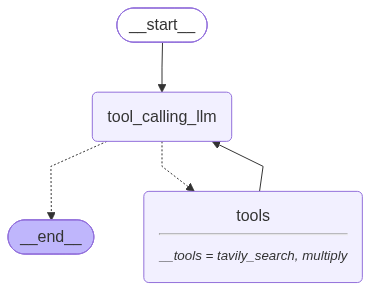

In [217]:
# In a ReAct Agent architecture:
# 1. The LLM receives the user's request.
# 2. The LLM decides which tool or tools need to be called.
# 3. The tools execute and return their results.
# 4. Those results are sent back to the LLM as observations.
# 5. The LLM reasons over the observations and decides whether another tool call is required.
# 6. This cycle continues until the LLM generates the final response.

from langgraph.graph import START,StateGraph
from langgraph.prebuilt import ToolNode,tools_condition

def tool_calling_llm(state:State):
  return {
    'messages':[llm_with_tool.invoke(state['messages'])]
  }

builder=StateGraph(State)

builder.add_node('tool_calling_llm',tool_calling_llm)
builder.add_node('tools',ToolNode(tools))

builder.add_edge(START,'tool_calling_llm')
builder.add_conditional_edges('tool_calling_llm',tools_condition)
builder.add_edge('tools','tool_calling_llm') ## we are send back the response to LLM

graph=builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))


In [218]:
# Now see the response
response=graph.invoke({"messages":"Give me the recent ai news and then multiply 5 by 10"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
================================== Ai Message ==================================

[]
Tool Calls:
  tavily_search (call_366557)
 Call ID: call_366557
  Args:
    topic: news
    query: latest AI news 2025
  multiply (call_366558)
 Call ID: call_366558
  Args:
    a: 5
    b: 10
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news 2025", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://pressgazette.co.uk/platforms/news-publisher-ai-deals-lawsuits-openai-google", "title": "Who’s suing AI and who’s signing latest: Canadian publishers sue Anthropic, Reach and CNN are latest Google AI news partners", "content": "_26 November 2025:_Nine regional newspaper publishers in the US owned or managed by Media News Group (a subsidiary of Alden Global Capita

### Added Memory In Agentic Graph

In [219]:
## Lets see without memory what will happen
response=graph.invoke({"messages":"Hi my name is durga prasad"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Hi my name is durga prasad
================================== Ai Message ==================================

[{'type': 'text', 'text': "Hello Durga Prasad! It's nice to meet you. How can I help you today?", 'extras': {'signature': 'EmAKXgFpFH0TQCsBL/NSRsDvmrMFu28nDa0Ip6M83Q0z9l+/lIz8xceAlhlwwwvXfGCEqW1osBf0ObbUdRFzNGe4lclwxIKyd1xi9Nvz5FWeajfXPO3DDNB2kff2dku8B9E='}}]


In [220]:
## Now again test your agent whether its able to remember the name or not
response=graph.invoke({"messages":"Hi what is my name??"})
for m in response['messages']:
    m.pretty_print()

#basically it couldn't remember your name because we are not persist the conversation state
# In order to avoid this problem we use memory

================================ Human Message =================================

Hi what is my name??
================================== Ai Message ==================================

[{'type': 'text', 'text': "Hello! I don't know your name yet, as this is our first time chatting. What would you like me to call you?", 'extras': {'signature': 'EmAKXgFpFH0TTbFEz1t3yx/wmvGcGIXZAw3sNJjSXt4lgp0PEGxmZsyBAR+RHJXdavyynTwmNW9sUdEIS62dPRly4pJSX8QXJVD3sL5snSmox5cW9aQTRdOfUJBW2YLQ930='}}]


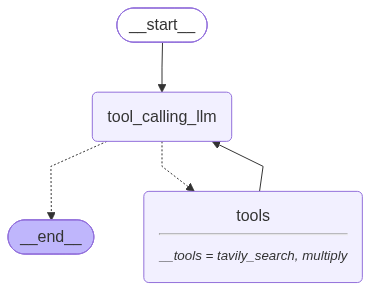

In [221]:
## Adding memory to Agentic Graph
from langgraph.graph import START,StateGraph
from langgraph.prebuilt import ToolNode,tools_condition
from langgraph.checkpoint.memory import MemorySaver ## It is used persit the conversation state with the help of threadId

## Define the memory
memory=MemorySaver()

def tool_calling_llm(state:State):
  return {
    'messages':[llm_with_tool.invoke(state['messages'])]
  }

builder=StateGraph(State)

builder.add_node('tool_calling_llm',tool_calling_llm)
builder.add_node('tools',ToolNode(tools))

builder.add_edge(START,'tool_calling_llm')
builder.add_conditional_edges('tool_calling_llm',tools_condition)
builder.add_edge('tools','tool_calling_llm') ## we are send back the response to LLM

graph=builder.compile(checkpointer=memory) # Now add the memory in compile

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [222]:
## create the config
config={'configurable':{'thread_id':'1'}}

In [223]:
## Now invoke the agentic graph with config to check whether it is presisting or not
response=graph.invoke({'messages':'Hi my name is DurgaPrasad'},config=config)
for m in response['messages']:
  m.pretty_print()

================================ Human Message =================================

Hi my name is DurgaPrasad
================================== Ai Message ==================================

[{'type': 'text', 'text': "Hello DurgaPrasad! It's nice to meet you. How can I help you today?", 'extras': {'signature': 'EmAKXgFpFH0ToZKGTvEt6b3Lm+Bz5xkBAoylwTYjCrMKw9FWkTj4OZiKfsN2eZKGgsWf47PG0ohF4cvxGRwz38PtsY6o1QaY+1c1b2xf+EPjcB97jRuMj5Ke/P7XhMpan18='}}]


In [224]:
## Now check whether the ai is remebering or not
response=graph.invoke({'messages':'Hi please tell my name'},config=config)
for m in response['messages']:
  m.pretty_print()

## see here the output, the AI is remebering the name ,that is the magic of adding memory to the agent  

================================ Human Message =================================

Hi my name is DurgaPrasad
================================== Ai Message ==================================

[{'type': 'text', 'text': "Hello DurgaPrasad! It's nice to meet you. How can I help you today?", 'extras': {'signature': 'EmAKXgFpFH0ToZKGTvEt6b3Lm+Bz5xkBAoylwTYjCrMKw9FWkTj4OZiKfsN2eZKGgsWf47PG0ohF4cvxGRwz38PtsY6o1QaY+1c1b2xf+EPjcB97jRuMj5Ke/P7XhMpan18='}}]
================================ Human Message =================================

Hi please tell my name
================================== Ai Message ==================================

[{'type': 'text', 'text': 'Your name is DurgaPrasad!', 'extras': {'signature': 'EmAKXgFpFH0TvaxsG/07K/L1QIjGZ439ZWGcfxSYuqLih510PbA2wEmjFwz17PpI2GMxnoKtrpAPIpMg+irifmJ++7cgmrzo5LYtj8Oh8UOGWz8BaFmvZ4Upbr59o+/hNAg='}}]


### Streaming

- streaming is nothing but sending reponse in pieces as soon as available instead of waiting the entire response 
- It is good for chatbots
- streaming have two methods 
  - stream: Streams outputs synchronously,one chunk at a time
  - astream: Stremas outputs asynchronously,one chunk at a time
- modes in streaming
  - values: Gives the complete state after each graph step
  - updates: Gives the state changes made by node

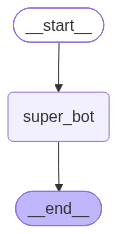

In [236]:
from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import START, StateGraph ,END
memory=MemorySaver()

def super_bot(state:State):
  return {
    'messages':[llm.invoke(state['messages'])]
  }

graph_builder=StateGraph(State)

graph_builder.add_node('super_bot',super_bot)

graph_builder.add_edge(START,'super_bot')
graph_builder.add_edge('super_bot',END)

graph=graph_builder.compile(checkpointer=memory)

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [ ]:
# In Cell 35 (where you used values): 
# The LLM chose Choice A. It decided to call tavily_search. That is why content=[] was empty and tool_calls had the search query.

# In Cell 36 (where you used updates): 
# The LLM chose Choice B. It decided to answer directly from memory without calling any tool. If you look at that chunk, tool_calls=[] is empty and content has the full text.

In [237]:
## generate the response using stream
## here the mode is 'values'

config = {
    'configurable': {
        'thread_id': "4"
    }
}

response = graph.stream(
    {'messages': "what is langgraph?"},
    config,
    stream_mode='values'
)

for chunk in response:
    print(chunk)

{'messages': [HumanMessage(content='what is langgraph?', additional_kwargs={}, response_metadata={}, id='b44cdec7-88bb-4c1f-aaf2-d19274eb23f0')]}
{'messages': [HumanMessage(content='what is langgraph?', additional_kwargs={}, response_metadata={}, id='b44cdec7-88bb-4c1f-aaf2-d19274eb23f0'), AIMessage(content=[{'type': 'text', 'text': '**LangGraph** is an open-source library developed by LangChain designed to build **stateful, multi-agent applications** with Large Language Models (LLMs). \n\nIf LangChain is like a set of Lego bricks for building simple LLM chains, LangGraph is the framework for building complex workflows where agents need to **loop, make decisions, remember state, and collaborate** over multiple steps.\n\nHere is a breakdown of why LangGraph exists and what makes it unique:\n\n---\n\n### 1. The Problem It Solves\nStandard LLM chains are usually **Directed Acyclic Graphs (DAGs)**—they flow in a straight line: *Input $\\rightarrow$ Prompt $\\rightarrow$ LLM $\\rightarrow$ 

In [238]:
## generate the response using stream
## here the mode is 'updates'

config = {
    'configurable': {
        'thread_id': "4"
    }
}

response = graph.stream(
    {'messages': "what is langgraph?"},
    config,
    stream_mode='updates'
)

for chunk in response:
    print(chunk)

{'super_bot': {'messages': [AIMessage(content=[{'type': 'text', 'text': '**LangGraph** is an open-source programming framework built by the creators of LangChain. It is designed for building **stateful, multi-agent applications** powered by Large Language Models (LLMs). \n\nIf standard LLM tools are like a straight assembly line, LangGraph is designed for complex workflows where AI agents need to **loop, make decisions, collaborate, and remember context** over multiple steps.\n\nHere is a breakdown of what makes it unique and why it’s useful:\n\n---\n\n### 1. The Core Problem It Solves\nMost traditional LLM applications follow a straight path (a Directed Acyclic Graph, or DAG): *User input $\\rightarrow$ Prompt $\\rightarrow$ LLM $\\rightarrow$ Output.*\n\nHowever, advanced AI tasks—like autonomous coding, complex research, or multi-step problem-solving—require **loops and conditional logic**. For example:\n* *Write code $\\rightarrow$ Run tests $\\rightarrow$ Did it fail? If yes, rewr

### Asynchronous stream
- In asynchronous operation,while one operation is waiting for another response,the application can work on other tasks

In [240]:
config = {
    'configurable': {
        'thread_id': "5"
    }
}

response = graph.astream(
    {'messages': "what is langgraph?"},
    config,
    stream_mode='updates'
)

async for chunk in response:
    print(chunk)

{'super_bot': {'messages': [AIMessage(content=[{'type': 'text', 'text': '**LangGraph** is an open-source library developed by LangChain designed to build **stateful, multi-agent applications** with Large Language Models (LLMs). \n\nIf LangChain helps you build single-turn or simple chain-based AI interactions, LangGraph helps you build complex, cyclical workflows where multiple AI agents can collaborate, make decisions, remember past actions, and loop until a problem is solved.\n\nHere is a breakdown of what makes LangGraph unique and why it is used:\n\n---\n\n### 1. Why Do We Need LangGraph?\nTraditional LLM applications usually follow a **Directed Acyclic Graph (DAG)**—meaning the data flows in a straight line from Step A to Step B to Step C. \n\nHowever, real-world problem-solving requires **loops and iteration**. For example:\n* An agent writes code.\n* It tests the code.\n* If the code fails, it goes *back* to the writing step to fix the error (a loop).\n* It repeats this until th